In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense, Embedding, Flatten, Concatenate
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [15]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [16]:
symbols = ["AAPL","AIG", "BAC", "GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx", parse_dates=[0])
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Υπολογίζουμε το Trend ΜΟΝΟ μέσα στα δεδομένα αυτής της μετοχής
    df["Trend"] = df.iloc[:,3].shift(-30)/df.iloc[:,3]
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

features_trend = [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 19, 20, 21]

X_trend_num = dataset.iloc[:, features_trend]
X_trend_sym = dataset["Symbol_enc"]
y_trend = dataset['Trend']

dates = dataset.index

valid_idx = y_trend.notna()
X_trend_num = X_trend_num.loc[valid_idx]
X_trend_sym = X_trend_sym.loc[valid_idx]
y_trend = np.log1p(y_trend.loc[valid_idx])

In [17]:
print(X_trend_num)
print(X_trend_sym)
print(y_trend)

                 Open       High        Low      Close      RSI      SMA  \
Date                                                                       
2019-01-02  36.985080  37.930661  36.827482  37.708591  38.1140  44.1389   
2019-01-03  34.379965  34.795449  33.907176  33.952545  27.9036  43.7742   
2019-01-04  34.511295  35.471204  34.336985  35.401955  35.1259  43.4322   
2019-01-07  35.507026  35.538069  34.838433  35.323162  34.9211  43.0787   
2019-01-08  35.712380  36.252032  35.464047  35.996532  38.2354  42.7750   
...               ...        ...        ...        ...      ...      ...   
2024-11-11   6.450000   7.700000   6.383000   7.550000  58.1338   6.5396   
2024-11-12   7.370000   7.700000   6.710000   7.060000  52.6522   6.5576   
2024-11-13   7.340000   8.190000   7.070000   7.080000  52.8477   6.5734   
2024-11-14   7.250000   7.441000   6.495000   6.580000  47.5622   6.5842   
2024-11-15   6.600000   6.945000   6.590000   6.770000  49.6240   6.6028   

           

In [18]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_trend_num.loc[X_trend_num.index.isin(train_dates)]
X_sym_train = X_trend_sym.loc[X_trend_sym.index.isin(train_dates)]
y_train = y_trend.loc[y_trend.index.isin(train_dates)]

X_num_test = X_trend_num.loc[X_trend_num.index.isin(test_dates)]
X_sym_test = X_trend_sym.loc[X_trend_sym.index.isin(test_dates)]
y_test = y_trend.loc[y_trend.index.isin(test_dates)]

val_size = 0.2
val_len = int(len(train_dates) * val_size)

train_dates_final = train_dates[:-val_len]
val_dates = train_dates[-val_len:]

X_num_train_final = X_trend_num.loc[X_trend_num.index.isin(train_dates_final)]
X_sym_train_final = X_trend_sym.loc[X_trend_sym.index.isin(train_dates_final)]
y_train_final = y_trend.loc[y_trend.index.isin(train_dates_final)]

X_num_val = X_trend_num.loc[X_trend_num.index.isin(val_dates)]
X_sym_val = X_trend_sym.loc[X_trend_sym.index.isin(val_dates)]
y_val = y_trend.loc[y_trend.index.isin(val_dates)]

In [19]:
test_df = pd.concat([X_num_test,X_sym_test.rename("Symbol"),y_test.rename("Target")],axis=1)

# Αποθήκευση στο Google Drive
save_path = "/content/drive/MyDrive/test_set_trend_aligned.csv"
test_df.to_csv(save_path)

print(f"Test set αποθηκεύτηκε στο: {save_path}")

Test set αποθηκεύτηκε στο: /content/drive/MyDrive/test_set_trend_aligned.csv


In [20]:
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [21]:
num_input = Input(shape=(X_num_train_final.shape[1],), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

embed_dim = 2
sym_embed = Embedding(input_dim=num_symbols,output_dim=embed_dim,name="symbol_embedding")(sym_input)
sym_embed = Flatten()(sym_embed)
x = Concatenate()([num_input, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model(inputs=[num_input, sym_input], outputs=output)
model.compile(optimizer=Adam(learning_rate=0.0005), loss = 'mse', metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history=model.fit([X_num_train_final, X_sym_train_final],y_train_final,validation_data=([X_num_val, X_sym_val], y_val),batch_size = 16, epochs = 1000,callbacks=[early_stopping])

Epoch 1/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0507 - mae: 0.1557 - mape: 22.2244 - rmse: 0.2252 - val_loss: 0.0321 - val_mae: 0.1438 - val_mape: 21.2588 - val_rmse: 0.1793
Epoch 2/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0133 - mae: 0.0855 - mape: 12.3179 - rmse: 0.1155 - val_loss: 0.0317 - val_mae: 0.1465 - val_mape: 21.4396 - val_rmse: 0.1781
Epoch 3/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0097 - mae: 0.0711 - mape: 10.2812 - rmse: 0.0987 - val_loss: 0.0251 - val_mae: 0.1292 - val_mape: 19.3416 - val_rmse: 0.1586
Epoch 4/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0082 - mae: 0.0644 - mape: 9.3457 - rmse: 0.0904 - val_loss: 0.0229 - val_mae: 0.1242 - val_mape: 18.4702 - val_rmse: 0.1513
Epoch 5/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0073 - mae: 0.0603 - mape: 8.7502 - rmse: 0.0855 - val_loss: 0.0216 - val_mae: 0.1200 - val_mape: 17.7099 - val_rmse: 0.1470
Epoch 6/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/ste

In [22]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([X_num_test,X_sym_test], y_test)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0129 - mae: 0.0861 - mape: 12.9283 - rmse: 0.1134
Test Loss (MSE): 0.012856585904955864, Test MAE: 0.0860690027475357


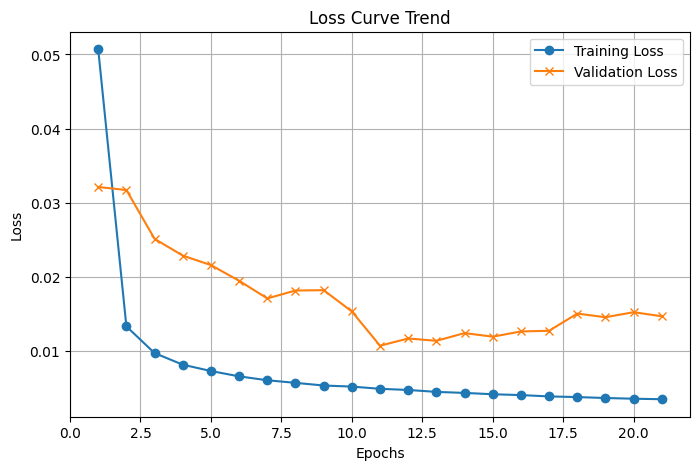

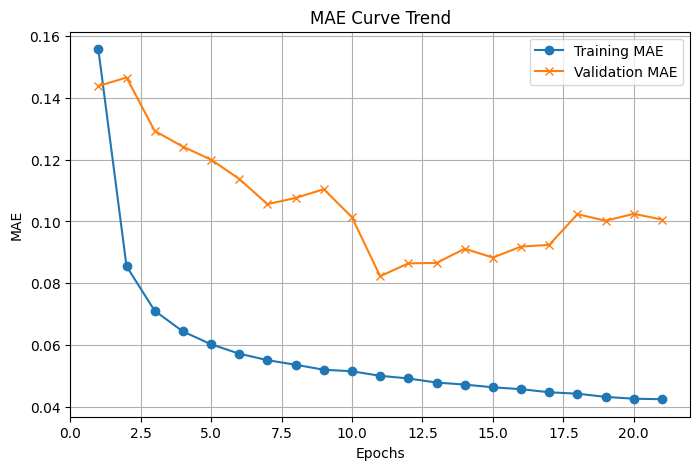

In [23]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Trend')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Trend')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
y_pred = model.predict([X_num_test,X_sym_test])

y_test = y_test.to_numpy().reshape(-1, 1)

y_pred = np.expm1(y_pred)
y_test = np.expm1(y_test)

mae  = mean_absolute_error((y_test), (y_pred))
rmse = np.sqrt(mean_squared_error((y_test), (y_pred)))
mape = np.mean(np.abs(((y_test) - (y_pred)) / (y_test))) * 100
r2   = r2_score((y_test), (y_pred))
relative_mae= mae / np.mean(y_test) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE : {relative_mae:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE  : 0.17
RMSE : 0.22
MAPE : 17.75%
R²   : -1.462
Relative MAE : 16.86%
